# MODULE 2 END ASSIGNMENT: ABC COMPANY 

### STEP  1: importing dataset and the tools

In [455]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
data=pd.read_csv("ABC Company Dataset.csv")
data.head(3)

,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,06-Feb,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,06-Jun,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,06-May,205,Boston University,NaN


In [456]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 458 entries, 0 to 457
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      458 non-null    str    
 1   Team      458 non-null    str    
 2   Number    458 non-null    int64  
 3   Position  458 non-null    str    
 4   Age       458 non-null    int64  
 5   Height    458 non-null    str    
 6   Weight    458 non-null    int64  
 7   College   374 non-null    str    
 8   Salary    447 non-null    float64
dtypes: float64(1), int64(3), str(5)
memory usage: 52.0 KB


### STEP 2: cleaning the dataset

In [457]:
data.dropna( inplace=True,ignore_index=True)

In [458]:
h_data=np.array(np.random.randint(150,180,size=(365)))
data["Height"]=h_data
data["Height"].astype("int64")
data

,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,161,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,151,235,Marquette,6796117.0
2,R.J. Hunter,Boston Celtics,28,SG,22,169,185,Georgia State,1148640.0
3,Jordan Mickey,Boston Celtics,55,PF,21,175,235,LSU,1170960.0
4,Kelly Olynyk,Boston Celtics,41,C,25,156,238,Gonzaga,2165160.0
...,...,...,...,...,...,...,...,...,...
360,Chris Johnson,Utah Jazz,23,SF,26,159,206,Dayton,981348.0
361,Trey Lyles,Utah Jazz,41,PF,20,166,234,Kentucky,2239800.0
362,Shelvin Mack,Utah Jazz,8,PG,26,163,203,Butler,2433333.0
363,Jeff Withey,Utah Jazz,24,C,26,169,231,Kansas,947276.0


In [459]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      365 non-null    str    
 1   Team      365 non-null    str    
 2   Number    365 non-null    int64  
 3   Position  365 non-null    str    
 4   Age       365 non-null    int64  
 5   Height    365 non-null    int32  
 6   Weight    365 non-null    int64  
 7   College   365 non-null    str    
 8   Salary    365 non-null    float64
dtypes: float64(1), int32(1), int64(3), str(4)
memory usage: 38.8 KB


In [460]:
print(data.duplicated().value_counts())

False    365
Name: count, dtype: int64


### STEP 3: Analysing the data

##### TASK1: Determine the distribution of employees across each team and calculate the percentage split relative to the total number of employees

In [461]:
emp_distribution=data.groupby("Team")["Team"].value_counts().reset_index(name="emp_count_per_team")
x=emp_distribution["emp_count_per_team"].sum()
emp_distribution["percent_split"]= (emp_distribution["emp_count_per_team"]/x)*100
emp_distribution.sort_values("percent_split",ascending=False,ignore_index=True)

,Team,emp_count_per_team,percent_split
0,New Orleans Pelicans,16,4.383562
1,Detroit Pistons,15,4.109589
2,Portland Trail Blazers,15,4.109589
3,Oklahoma City Thunder,14,3.835616
4,Milwaukee Bucks,14,3.835616
5,Los Angeles Clippers,14,3.835616
6,Philadelphia 76ers,14,3.835616
7,Memphis Grizzlies,13,3.561644
8,Phoenix Suns,13,3.561644
9,Sacramento Kings,13,3.561644


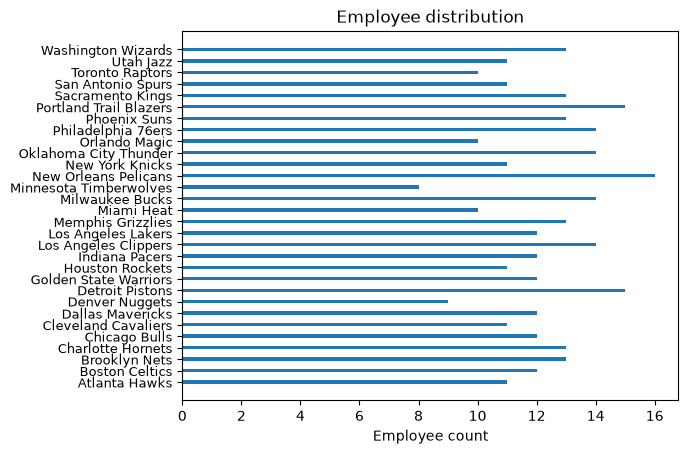

In [462]:
plt.barh(emp_distribution["Team"],emp_distribution["emp_count_per_team"],height=0.3)
plt.yticks(fontsize=9)
plt.xlabel("Employee count")
plt.title("Employee distribution")
plt.show()

###### ANALYSIS INSIGHT:
Employee headcount is evenly balanced across teams, ranging from 8 employees (Minnesota Timberwolves) to 16 employees (New Orleans Pelicans), with each team representing roughly 2% to 4.4% of the total workforce.

##### TASK2: Segregating employess based on their positions

In [463]:
SG_employees=pd.DataFrame(data.groupby("Position").get_group("SG")).reset_index(drop=True)
SG_employees

,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,R.J. Hunter,Boston Celtics,28,SG,22,169,185,Georgia State,1148640.0
1,Evan Turner,Boston Celtics,11,SG,27,178,220,Ohio State,3425510.0
2,James Young,Boston Celtics,13,SG,20,173,215,Kentucky,1749840.0
3,Markel Brown,Brooklyn Nets,22,SG,24,151,190,Oklahoma State,845059.0
4,Wayne Ellington,Brooklyn Nets,21,SG,28,162,200,North Carolina,1500000.0
...,...,...,...,...,...,...,...,...,...
82,Gerald Henderson,Portland Trail Blazers,9,SG,28,178,215,Duke,6000000.0
83,C.J. McCollum,Portland Trail Blazers,3,SG,24,171,200,Lehigh,2525160.0
84,Luis Montero,Portland Trail Blazers,44,SG,23,161,185,Westchester CC,525093.0
85,Alec Burks,Utah Jazz,10,SG,24,165,214,Colorado,9463484.0


In [464]:
PF_employees=pd.DataFrame(data.groupby("Position").get_group("PF")).reset_index(drop=True)
PF_employees

,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Jordan Mickey,Boston Celtics,55,PF,21,175,235,LSU,1170960.0
1,Chris McCullough,Brooklyn Nets,1,PF,21,163,200,Syracuse,1140240.0
2,Willie Reed,Brooklyn Nets,33,PF,26,155,220,Saint Louis,947276.0
3,Thomas Robinson,Brooklyn Nets,41,PF,25,174,237,Kansas,981348.0
4,Thaddeus Young,Brooklyn Nets,30,PF,27,171,221,Georgia Tech,11235955.0
...,...,...,...,...,...,...,...,...,...
76,Meyers Leonard,Portland Trail Blazers,11,PF,24,168,245,Illinois,3075880.0
77,Noah Vonleh,Portland Trail Blazers,21,PF,20,178,240,Indiana,2637720.0
78,Trevor Booker,Utah Jazz,33,PF,28,158,228,Clemson,4775000.0
79,Derrick Favors,Utah Jazz,15,PF,24,160,265,Georgia Tech,12000000.0


In [465]:
PG_employees=pd.DataFrame(data.groupby("Position").get_group("PG")).reset_index(drop=True)
PG_employees

,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,161,180,Texas,7730337.0
1,Terry Rozier,Boston Celtics,12,PG,22,161,190,Louisville,1824360.0
2,Marcus Smart,Boston Celtics,36,PG,22,163,220,Oklahoma State,3431040.0
3,Isaiah Thomas,Boston Celtics,4,PG,27,161,185,Washington,6912869.0
4,Jarrett Jack,Brooklyn Nets,2,PG,32,168,200,Georgia Tech,6300000.0
...,...,...,...,...,...,...,...,...,...
71,Russell Westbrook,Oklahoma City Thunder,0,PG,27,177,200,UCLA,16744218.0
72,Damian Lillard,Portland Trail Blazers,0,PG,25,175,195,Weber State,4236287.0
73,Brian Roberts,Portland Trail Blazers,2,PG,30,153,173,Dayton,2854940.0
74,Trey Burke,Utah Jazz,3,PG,23,165,191,Michigan,2658240.0


In [466]:
SF_employees=pd.DataFrame(data.groupby("Position").get_group("SF")).reset_index(drop=True)
SF_employees

,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Jae Crowder,Boston Celtics,99,SF,25,151,235,Marquette,6796117.0
1,Carmelo Anthony,New York Knicks,7,SF,32,160,240,Syracuse,22875000.0
2,Cleanthony Early,New York Knicks,11,SF,25,157,210,Wichita State,845059.0
3,Lance Thomas,New York Knicks,42,SF,28,156,235,Duke,1636842.0
4,Robert Covington,Philadelphia 76ers,33,SF,25,172,215,Tennessee State,1000000.0
...,...,...,...,...,...,...,...,...,...
66,Kyle Singler,Oklahoma City Thunder,5,SF,28,161,228,Duke,4500000.0
67,Al-Farouq Aminu,Portland Trail Blazers,8,SF,25,161,215,Wake Forest,8042895.0
68,Maurice Harkless,Portland Trail Blazers,4,SF,23,152,215,St. John's,2894059.0
69,Gordon Hayward,Utah Jazz,20,SF,26,158,226,Butler,15409570.0


In [467]:
C_employees=pd.DataFrame(data.groupby("Position").get_group("C")).reset_index(drop=True)
C_employees

,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Kelly Olynyk,Boston Celtics,41,C,25,156,238,Gonzaga,2165160.0
1,Jared Sullinger,Boston Celtics,7,C,24,165,260,Ohio State,2569260.0
2,Tyler Zeller,Boston Celtics,44,C,26,177,253,North Carolina,2616975.0
3,Brook Lopez,Brooklyn Nets,11,C,28,160,275,Stanford,19689000.0
4,Henry Sims,Brooklyn Nets,14,C,26,168,248,Georgetown,947276.0
5,Robin Lopez,New York Knicks,8,C,28,160,255,Stanford,12650000.0
6,Joel Embiid,Philadelphia 76ers,21,C,22,158,250,Kansas,4626960.0
7,Jahlil Okafor,Philadelphia 76ers,8,C,20,176,275,Duke,4582680.0
8,Andrew Bogut,Golden State Warriors,12,C,31,168,260,Utah,13800000.0
9,Festus Ezeli,Golden State Warriors,31,C,26,156,265,Vanderbilt,2008748.0


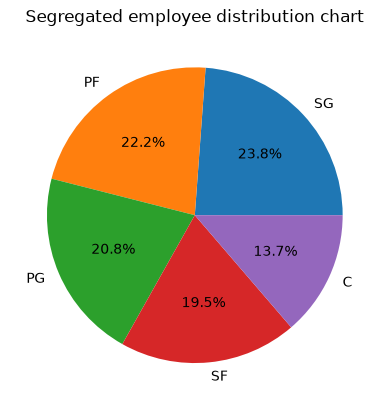

In [468]:
a=data["Position"].value_counts().reset_index()
plt.pie(a["count"],labels=a["Position"],autopct="%1.1f%%")
plt.title("Segregated employee distribution chart")
plt.show()

###### ANALYSIS INSIGHT: 
Employee distribution across positions is fairly balanced among SG (23.8%), PF (22.2%), PG (20.8%), and SF (19.5%), while C accounts for the smallest share at 13.7%.

##### TASK3: finding the predominant age group

In [469]:
sorted_age=data.groupby("Age")["Age"].count().reset_index(name="COUNT")
sorted_age.sort_values("COUNT",ascending=False,ignore_index=True)

,Age,COUNT
0,25,42
1,24,41
2,27,35
3,23,33
4,26,32
5,28,27
6,22,23
7,30,20
8,31,17
9,29,17


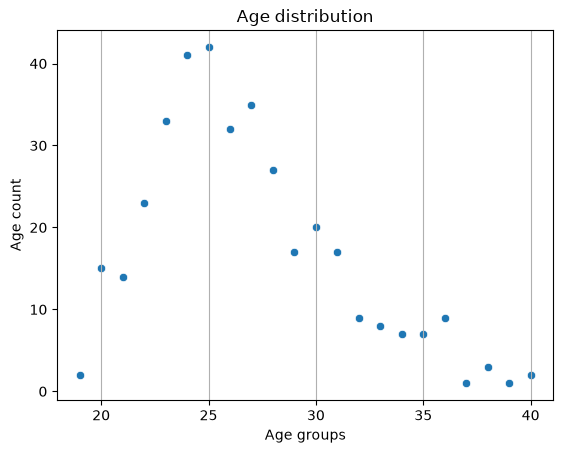

In [470]:
sns.scatterplot(data=sorted_age,x=sorted_age["Age"],y=sorted_age["COUNT"])
plt.xlabel("Age groups")
plt.ylabel("Age count")
plt.title("Age distribution")
plt.grid(axis="x")
plt.show()

###### ANALYSIS INSIGHT:
Employee ages span from 19 to 40 with a right-skewed distribution peaking around ages 24–25 (roughly 41–42 employees), concentrated primarily in the mid-20s before dropping below 10 employees per age from age 32 onward.

##### TASK 4:Discover which team and position have the highest salary expenditure.

In [471]:
tandp_exp=data.groupby(["Team","Position"])["Salary"].max().reset_index(name="max salary")
tandp_exp["max salary"]=tandp_exp["max salary"]/1e6
tandp_exp=tandp_exp.sort_values("max salary",ascending=False,ignore_index=True).head(10)
tandp_exp

,Team,Position,max salary
0,New York Knicks,SF,22.875000
1,Miami Heat,PF,22.192730
2,Los Angeles Clippers,PG,21.468695
3,Oklahoma City Thunder,SF,20.158622
4,Chicago Bulls,PG,20.093064
5,Miami Heat,SG,20.000000
6,Cleveland Cavaliers,PF,19.689000
7,Los Angeles Clippers,C,19.689000
8,Brooklyn Nets,C,19.689000
9,San Antonio Spurs,PF,19.689000


In [472]:
t_exp=data.groupby("Team")["Salary"].max().reset_index()
t_exp["Salary"]=t_exp["Salary"]/1e6
t_exp=t_exp.sort_values("Salary",ascending=False,ignore_index=True).head(10)
t_exp

,Team,Salary
0,New York Knicks,22.875000
1,Miami Heat,22.192730
2,Los Angeles Clippers,21.468695
3,Oklahoma City Thunder,20.158622
4,Chicago Bulls,20.093064
5,Cleveland Cavaliers,19.689000
6,San Antonio Spurs,19.689000
7,Brooklyn Nets,19.689000
8,Atlanta Hawks,18.671659
9,Indiana Pacers,17.120106


In [473]:
p_exp=data.groupby("Position")["Salary"].max().reset_index()
p_exp["Salary"]=p_exp["Salary"]/1e6
p_exp=p_exp.sort_values("Salary",ascending=False,ignore_index=True)
p_exp

,Position,Salary
0,SF,22.875000
1,PF,22.192730
2,PG,21.468695
3,SG,20.000000
4,C,19.689000


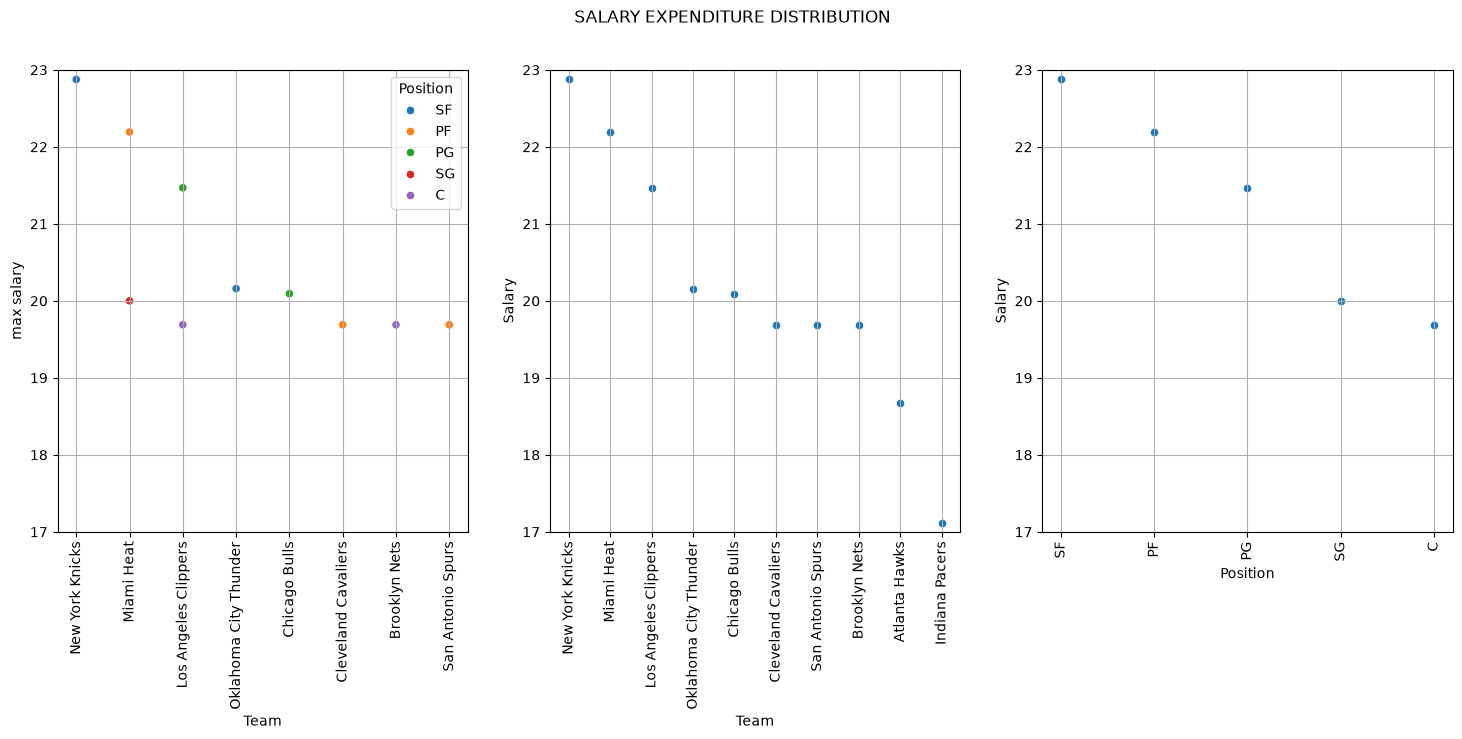

In [474]:
plt.figure(figsize=(18,6))
plt.subplot(1,3,1)
sns.scatterplot(data=tandp_exp.head(10),x="Team",y="max salary",hue="Position")
plt.xticks(rotation=90)
plt.ylim(17,23)
plt.grid()


plt.subplot(1,3,2)
sns.scatterplot(data=t_exp.head(10),x="Team",y="Salary")
plt.xticks(rotation=90)
plt.ylim(17,23)
plt.grid()


plt.subplot(1,3,3)
sns.scatterplot(data=p_exp.head(10),x="Position",y="Salary")
plt.xticks(rotation=90)
plt.ylim(17,23)
plt.grid()
plt.suptitle("SALARY EXPENDITURE DISTRIBUTION")
plt.show()

###### ANALYSIS INSIGHT: 
Max salaries across the top groups peak near 22.9 for SF (New York Knicks) and step downward across teams (dropping as low as roughly 17.1 for Indiana Pacers) and across positions (from SF down to C around 19.7), while also showing that individual teams can hold multiple high-paying positions at different salary levels.

##### TASK 5:Correlation between Age and Salary

In [475]:
cor_data=data["Age"].corr(data["Salary"])
print(f"The correlation score between age and the salary within the data is {cor_data}")

The correlation score between age and the salary within the data is 0.15999189342806175


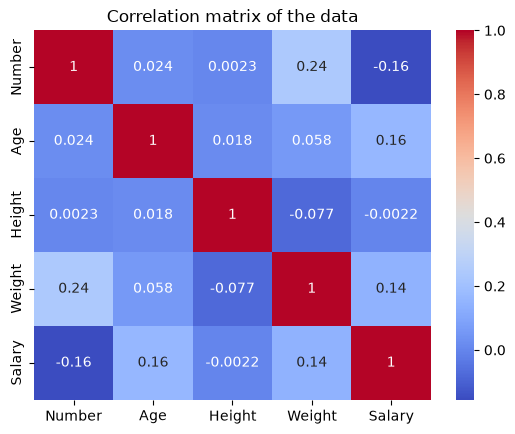

In [476]:
cor_data=data.corr(numeric_only=True)
sns.heatmap(data=cor_data,cmap="coolwarm",annot=True)
plt.title("Correlation matrix of the data")
plt.show()

###### ANALYSIS INSIGHT: 
Age and Salary show only a weak positive linear correlation (0.16), indicating that pay edges slightly higher with age, and the entire matrix shows a weak correlations across all numeric columns (-0.16 to 0.24).

### DATA STORY:

Employee headcount is evenly balanced across all 30 teams (8 to 16 employees per team) and largely consistent across core positions (SG, PF, PG, and SF around 19.5%–23.8%, with C smallest at 13.7%), while ages form a right-skewed profile peaking around 24–25 before tapering off after age 32. Maximum salaries reach nearly 22.9M (SF on the New York Knicks) and step down across teams and positions, with individual teams able to hold multiple top-paying roles at different tiers. Meanwhile, numeric correlations across the dataset are weak overall (-0.16 to 0.24), including only a weak positive link between Age and Salary (0.16). Together, these patterns show a young, evenly staffed organization where peak compensation is shaped more by team and position than by age or linear numeric trends.